# Bank Marketing Prediction (Simplified)

**Goal:** predict whether a bank customer will subscribe to a term deposit (`y`: yes / no) using supervised machine learning.

**Dataset:** UCI Bank Marketing, `bank-full.csv` (45,211 rows, 16 input columns + target `y`).
Citation: Moro, S., Rita, P., & Cortez, P. (2014). *Bank Marketing*. UCI Machine Learning Repository. https://doi.org/10.24432/C5K306

**Steps:** load data → clean → preprocess → train 4 models → evaluate → compare.

## 1. Import libraries and load dataset

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

RANDOM_STATE = 42   # fixed seed so results are reproducible

In [2]:
df = pd.read_csv("bank-full.csv")   # the original file is only read, never changed

print("First five rows:")
display(df.head())
print("Shape (rows, columns):", df.shape)
print("Column names:", list(df.columns))

First five rows:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


Shape (rows, columns): (45211, 17)
Column names: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


## 2. Data cleaning

We only fix a problem if we actually find one. Every check below prints its result, and the summary at the end is built from those results.

In [3]:
# Check 1: missing values
missing_total = int(df.isna().sum().sum())
print("Missing values (total):", missing_total)

# Check 2: duplicate rows
duplicate_total = int(df.duplicated().sum())
print("Duplicate rows:", duplicate_total)

# Check 3: data types
print("\nData types:")
print(df.dtypes.to_string())

Missing values (total): 0
Duplicate rows: 0

Data types:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str


In [4]:
# Check 4: invalid values (rules based on what each column means)
invalid_checks = {
    "age not between 18 and 100":  ~df["age"].between(18, 100),
    "day not between 1 and 31":    ~df["day"].between(1, 31),
    "duration is negative":        df["duration"] < 0,
    "campaign is less than 1":     df["campaign"] < 1,
    "previous is negative":        df["previous"] < 0,
    "pdays below -1":              df["pdays"] < -1,
    "target not 'yes' or 'no'":    ~df["y"].isin(["yes", "no"]),
}
invalid_total = 0
for rule, mask in invalid_checks.items():
    n = int(mask.sum())
    invalid_total += n
    print(f"{rule:30s}: {n}")

# The text value "unknown" is a real category in this dataset, not an empty cell
print("\nColumns containing the category 'unknown':")
unknown_counts = (df == "unknown").sum()
print(unknown_counts[unknown_counts > 0].to_string())

age not between 18 and 100    : 0
day not between 1 and 31      : 0
duration is negative          : 0
campaign is less than 1       : 0
previous is negative          : 0
pdays below -1                : 0
target not 'yes' or 'no'      : 0

Columns containing the category 'unknown':
job            288
education     1857
contact      13020
poutcome     36959


In [5]:
# Apply cleaning ONLY where a problem was found
steps = []
if missing_total > 0:
    steps.append(f"{missing_total} missing cells found -> will be imputed in the pipeline (Section 3)")
else:
    steps.append("No missing values found -> nothing to fix")

if duplicate_total > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    steps.append(f"{duplicate_total} duplicate rows found -> removed")
else:
    steps.append("No duplicate rows found -> nothing removed")

if invalid_total > 0:
    steps.append(f"{invalid_total} invalid values found -> inspect before using the data")
else:
    steps.append("No invalid values found -> nothing to fix")

steps.append("'unknown' values kept as a normal category; outliers (e.g. large balances) kept because they are valid values")
steps.append("pdays = -1 means 'not previously contacted'; it is kept unchanged to preserve the original meaning")

print("CLEANING SUMMARY")
for i, s in enumerate(steps, 1):
    print(f" {i}. {s}")
print("\nDataset shape after cleaning:", df.shape)

CLEANING SUMMARY
 1. No missing values found -> nothing to fix
 2. No duplicate rows found -> nothing removed
 3. No invalid values found -> nothing to fix
 4. 'unknown' values kept as a normal category; outliers (e.g. large balances) kept because they are valid values
 5. pdays = -1 means 'not previously contacted'; it is kept unchanged to preserve the original meaning

Dataset shape after cleaning: (45211, 17)


## 3. Data preprocessing

* **Target:** `y` is converted to numbers (`yes = 1`, `no = 0`) and kept separate from the inputs.
* **`duration` is excluded.** It is the length of the last phone call, which is only known *after* the call. We want to predict *before* calling the customer, so using it would be **data leakage** (the model would use information from the future and look unrealistically good).
* **Numerical features:** fill missing values with the median, then standardise with `StandardScaler`.
* **Categorical features:** fill missing values with the most frequent value, then `OneHotEncoder`.
* **No leakage:** the preprocessing is placed *inside* each model's `Pipeline`, so it is fitted on the training data only and just applied to the test data.
* **Class imbalance:** most customers say "no", so every model uses `class_weight="balanced"` (mistakes on the rare "yes" class count more).

In [6]:
# Separate target and inputs; drop duration (leakage)
y = df["y"].map({"yes": 1, "no": 0})
X = df.drop(columns=["y", "duration"])

# Separate numerical and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = [col for col in X.columns if col not in numeric_features]
print("Numerical features  :", numeric_features)
print("Categorical features:", categorical_features)

# Preprocessing steps for each column type
numeric_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_steps = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("num", numeric_steps, numeric_features),
    ("cat", categorical_steps, categorical_features),
])

Numerical features  : ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [7]:
# Save the cleaned data (duration removed, y as 0/1) as a SEPARATE file; bank-full.csv is not touched.
# Scaling and one-hot encoding are NOT saved here: they happen inside the pipeline after the split.
processed = X.copy()
processed["y"] = y
processed.to_csv("processed_bank_marketing.csv", index=False)
print("Saved processed_bank_marketing.csv with shape", processed.shape)

Saved processed_bank_marketing.csv with shape (45211, 16)


In [8]:
# 80% training / 20% testing; stratify keeps the same yes/no ratio in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Training set:", X_train.shape, "| Test set:", X_test.shape)
print(f"Share of 'yes' -> all data: {y.mean():.3f} | train: {y_train.mean():.3f} | test: {y_test.mean():.3f}")

Training set: (36168, 15) | Test set: (9043, 15)
Share of 'yes' -> all data: 0.117 | train: 0.117 | test: 0.117


## 4. Model training

All four models are trained on the **same training split**, with the same preprocessing and balanced class weights (`class_weight="balanced"`, or the equivalent balanced sample weights for Gradient Boosting, which has no `class_weight` option). Settings are fixed in advance (not tuned on the test set).

| Model | Idea |
|---|---|
| Logistic Regression | Combines features into a probability using a weighted sum |
| Decision Tree | Asks a series of yes/no questions about the features (depth limited to avoid memorising the data) |
| Random Forest | Many decision trees that vote together |
| Gradient Boosting | Builds small trees one after another; each new tree tries to correct the mistakes of the previous ones |

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced",
                                              random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=50,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=10,
                                            class_weight="balanced", random_state=RANDOM_STATE,
                                            n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                                                    random_state=RANDOM_STATE),
}

# Gradient Boosting has no class_weight option, so we give the rare 'yes' class a larger
# sample weight instead (same idea as class_weight="balanced"; computed from training labels only)
balanced_weights = compute_sample_weight("balanced", y_train)

trained_models = {}
for name, model in models.items():
    # Pipeline = preprocessing + model, fitted on the training data only
    pipeline = Pipeline([("preprocessor", preprocessor), ("model", model)])
    if name == "Gradient Boosting":
        pipeline.fit(X_train, y_train, model__sample_weight=balanced_weights)
    else:
        pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print("Trained:", name)

Trained: Logistic Regression


Trained: Decision Tree


Trained: Random Forest


Trained: Gradient Boosting


## 5. Model evaluation

Every model is evaluated on the same untouched **test set**. Accuracy, precision, recall and F1 use the **predicted labels**; ROC-AUC uses the **predicted probabilities** of class 1 (`yes`). Precision, recall and F1 are for the `yes` class.

In [10]:
results = []
predictions = {}   # saved so the graphs in Section 6 can reuse them
for name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)                  # predicted labels (0 or 1)
    y_prob = pipeline.predict_proba(X_test)[:, 1]      # predicted probability of 'yes'
    predictions[name] = (y_pred, y_prob)

    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }
    results.append(scores)

    print(f"{name}")
    for metric, value in scores.items():
        if metric != "Model":
            print(f"   {metric:10s}: {value:.4f}")

Logistic Regression
   Accuracy  : 0.7548
   Precision : 0.2662
   Recall    : 0.6238
   F1-score  : 0.3732
   ROC-AUC   : 0.7722
Decision Tree
   Accuracy  : 0.8232
   Precision : 0.3428
   Recall    : 0.5577
   F1-score  : 0.4246
   ROC-AUC   : 0.7566


Random Forest
   Accuracy  : 0.8199
   Precision : 0.3468
   Recall    : 0.6106
   F1-score  : 0.4423
   ROC-AUC   : 0.7993
Gradient Boosting
   Accuracy  : 0.8018
   Precision : 0.3259
   Recall    : 0.6493
   F1-score  : 0.4340
   ROC-AUC   : 0.7996


## 6. Model comparison

The table is sorted by **ROC-AUC**, our primary selection metric, because it measures how well a model ranks likely subscribers above unlikely ones without depending on one fixed cut-off, and it is not fooled by class imbalance.

In [11]:
comparison = (pd.DataFrame(results)
              .set_index("Model")
              .sort_values("ROC-AUC", ascending=False)
              .round(4))
display(comparison)

best_model = comparison.index[0]
print(f"Best model by ROC-AUC: {best_model} (ROC-AUC = {comparison.loc[best_model, 'ROC-AUC']:.4f})")
for metric in ["Accuracy", "Precision", "Recall", "F1-score"]:
    print(f"Highest {metric:9s}: {comparison[metric].idxmax()} ({comparison[metric].max():.4f})")

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Gradient Boosting,0.8018,0.3259,0.6493,0.4340,0.7996
Random Forest,0.8199,0.3468,0.6106,0.4423,0.7993
Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722
Decision Tree,0.8232,0.3428,0.5577,0.4246,0.7566


Best model by ROC-AUC: Gradient Boosting (ROC-AUC = 0.7996)
Highest Accuracy : Decision Tree (0.8232)
Highest Precision: Random Forest (0.3468)
Highest Recall   : Gradient Boosting (0.6493)
Highest F1-score : Random Forest (0.4423)


### Graphs: comparing the models

Three graphs only: metric comparison, confusion matrices and ROC curves. All use the **test set**.

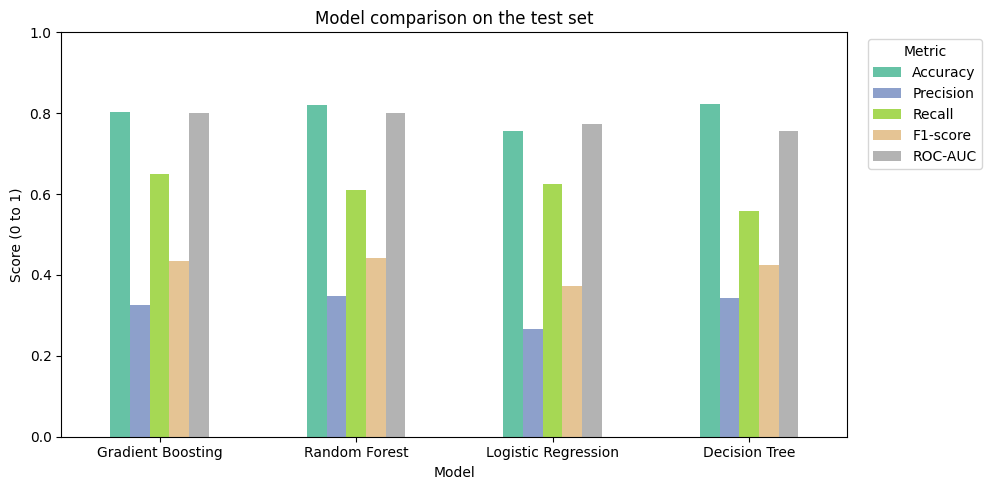

In [12]:
# Graph 1: all five metrics for the four models
ax = comparison.plot(kind="bar", figsize=(10, 5), rot=0, colormap="Set2")
ax.set_title("Model comparison on the test set")
ax.set_xlabel("Model")
ax.set_ylabel("Score (0 to 1)")
ax.set_ylim(0, 1)
ax.legend(title="Metric", loc="upper right", bbox_to_anchor=(1.18, 1))
plt.tight_layout()
plt.show()

**Graph 1** shows each metric side by side (higher is better). Compare bars of the *same colour* across models. Notice that a model can be best on one metric (e.g. accuracy) but not on another (e.g. recall).

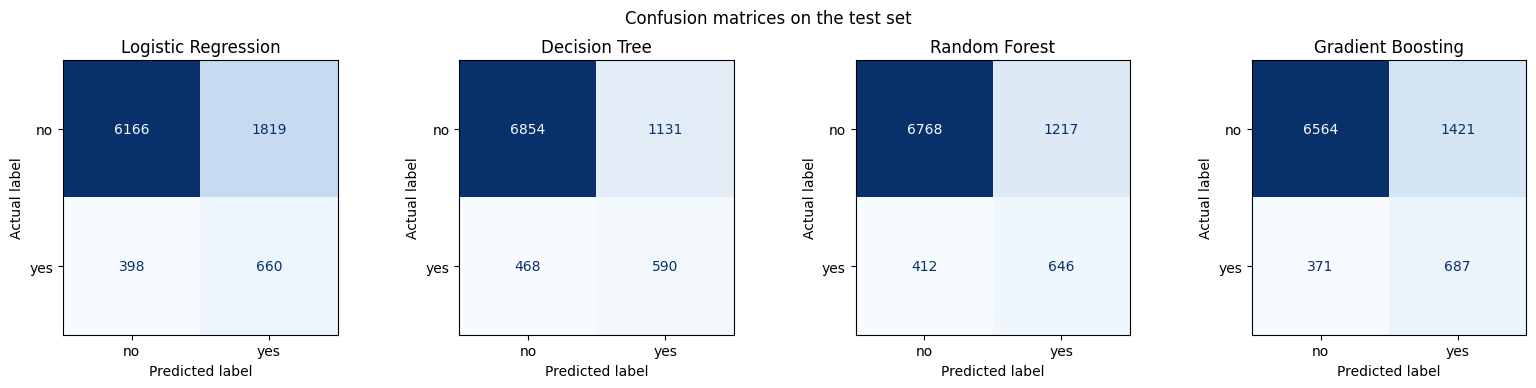

In [13]:
# Graph 2: confusion matrix of each model
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, (y_pred, y_prob)) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["no", "yes"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
fig.suptitle("Confusion matrices on the test set")
plt.tight_layout()
plt.show()

**Graph 2:** each square counts test customers. Bottom-right = real subscribers found (true positives); bottom-left = real subscribers missed (false negatives); top-right = customers wrongly predicted "yes" (wasted calls); top-left = correct "no" predictions.

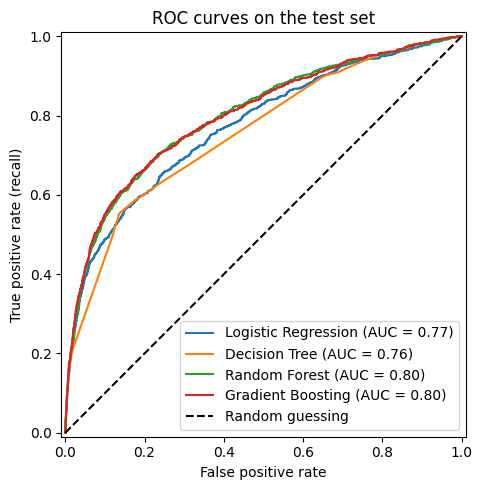

In [14]:
# Graph 3: ROC curves of the four models
fig, ax = plt.subplots(figsize=(6, 5))
for name, (y_pred, y_prob) in predictions.items():
    RocCurveDisplay.from_predictions(y_test, y_prob, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Random guessing")
ax.set_title("ROC curves on the test set")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Graph 3:** the closer a curve is to the top-left corner, the better the model ranks real subscribers above non-subscribers. The dashed diagonal is random guessing; the area under each curve is the ROC-AUC value in the table.

In [15]:
# Why accuracy alone can mislead: compare with a 'model' that always answers "no"
always_no_accuracy = 1 - y_test.mean()
print(f"Accuracy of always predicting 'no': {always_no_accuracy:.4f}")
print("Best trained-model accuracy        :", comparison["Accuracy"].max())

Accuracy of always predicting 'no': 0.8830
Best trained-model accuracy        : 0.8232


### What the metrics mean

* **Accuracy:** out of all customers, the share predicted correctly.
* **Precision:** out of customers predicted as "yes", the share who really subscribed (low precision = many wasted calls).
* **Recall:** out of customers who really subscribed, the share the model found (low recall = many missed customers).
* **F1-score:** one number balancing precision and recall.
* **ROC-AUC:** how well the model ranks customers (0.5 = random guessing, 1.0 = perfect).

### Why accuracy alone can be misleading

Only a small share of customers subscribe, so a useless model that always answers "no" already gets high accuracy (printed above) while finding **no** subscribers. Because we use `class_weight="balanced"`, our models deliberately accept some extra wrong "yes" predictions in order to find more real subscribers, which can even lower their accuracy below that baseline. That is why precision, recall, F1 and ROC-AUC are needed alongside accuracy.

*Note: the model that is "best" depends on the goal. ROC-AUC is used here as the single selection metric; if the bank cared most about not missing subscribers, recall would be weighted more.*